In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('/content/AB_NYC_2019.csv')

In [19]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [20]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [41]:
# Fill missing values in 'reviews_per_month' with the column's mean
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mean())

In [43]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


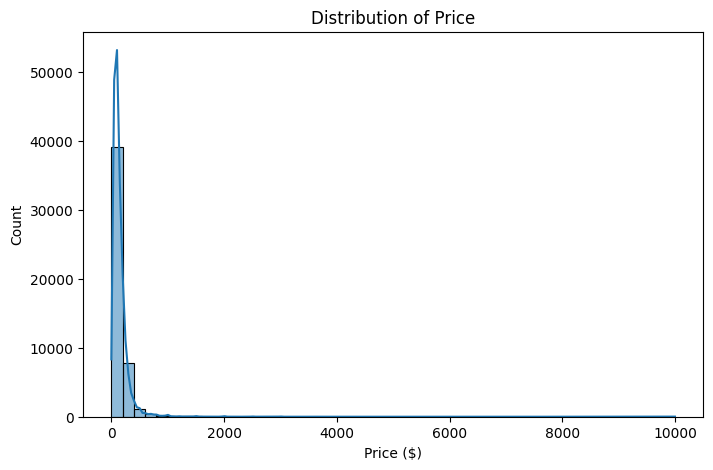

In [24]:
# Univariate Analysis for Price
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], kde=True, bins=50)
plt.title("Distribution of Price")
plt.xlabel("Price ($)")
plt.show()

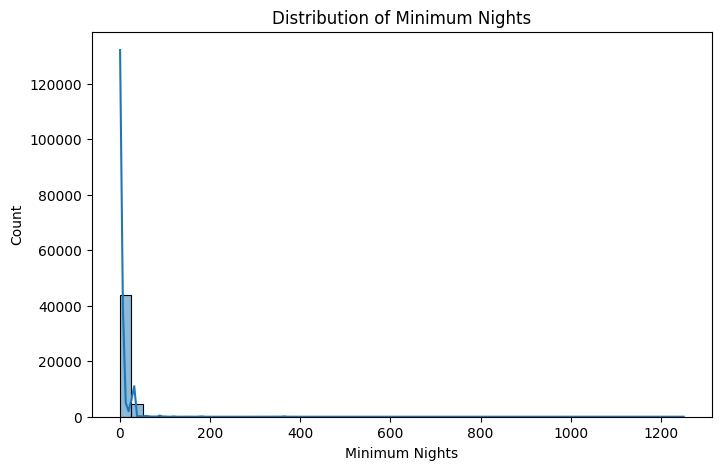

In [25]:
# Univariate Analysis for Minimum Nights
plt.figure(figsize=(8, 5))
sns.histplot(df['minimum_nights'], kde=True, bins=50)
plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.show()

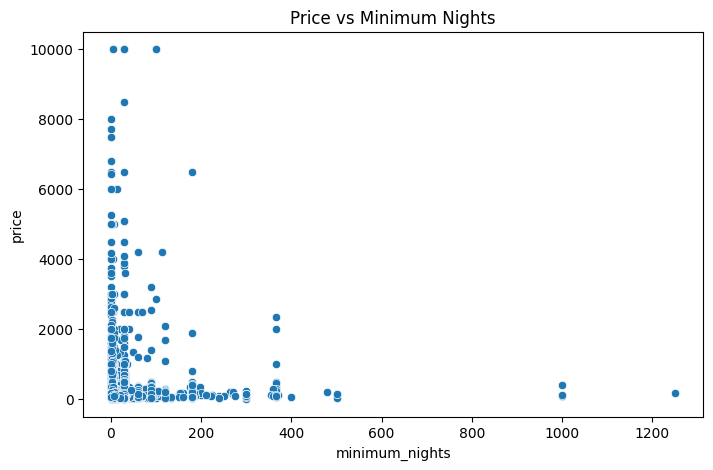

In [27]:
# Bivariate Analysis: Scatter plot (Numerical vs Numerical)
# Seeing how minimum nights required affects the price
plt.figure(figsize=(8, 5))
sns.scatterplot(x='minimum_nights', y='price', data=df)
plt.title("Price vs Minimum Nights")
plt.show()

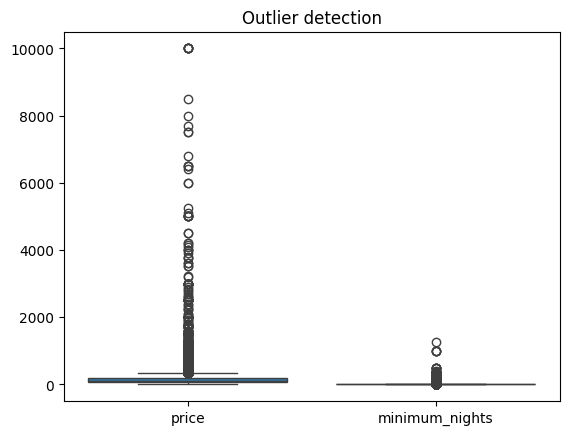

In [26]:
#Outlier Treatment
sns.boxplot(data=df[['price', 'minimum_nights']])
plt.title("Outlier detection")
plt.show()

In [28]:
# Outlier treatment using IQR and np.where
for col in ['price', 'minimum_nights']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Cap the outliers at the upper and lower bounds
    df[col] = np.where(df[col] > upper, upper, np.where(df[col] < lower, lower, df[col]))

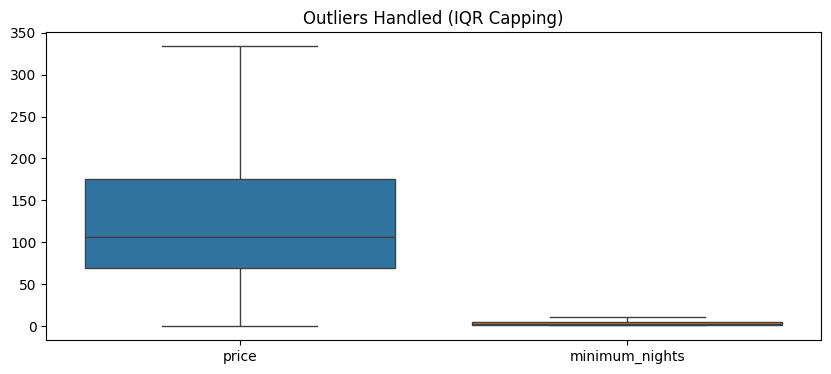

In [29]:
# Verify the treatment
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[['price', 'minimum_nights']])
plt.title("Outliers Handled (IQR Capping)")
plt.show()

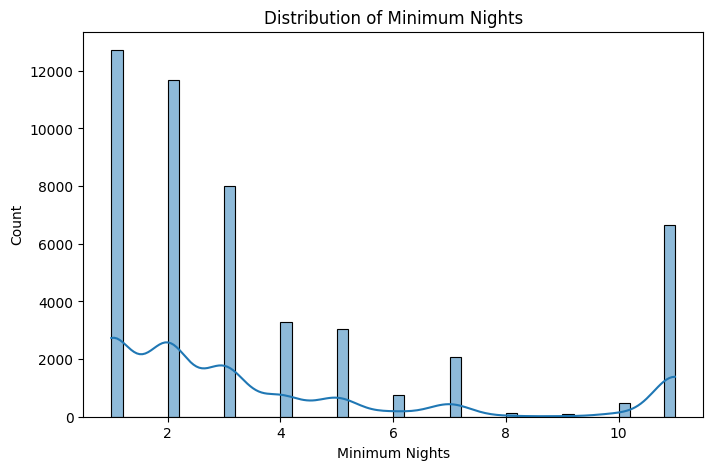

In [44]:
# Univariate Analysis for Minimum Nights
plt.figure(figsize=(8, 5))
sns.histplot(df['minimum_nights'], kde=True, bins=50)
plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.show()

In [30]:
# Separate x and y
X = df.drop(['price'], axis=1)
y = df['price']

In [31]:
from sklearn.model_selection import train_test_split

# Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
from sklearn.linear_model import LinearRegression

# Exclude other columns, leaving only 'minimum_nights' as the feature
X_train = X_train[['minimum_nights']]

# Initialize and fit the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [34]:
y_pred=model.predict(X_test[['minimum_nights']])

In [35]:
print(y_pred)

[132.1352627  142.83899114 130.79729665 ... 129.45933059 130.79729665
 132.1352627 ]


In [37]:
results=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(results)

       Actual   Predicted
879      89.0  132.135263
44383    30.0  142.838991
15394   120.0  130.797297
43230   334.0  130.797297
16332   199.0  130.797297
...       ...         ...
20477   215.0  130.797297
44969   100.0  129.459331
36577    70.0  129.459331
11477   334.0  130.797297
1023    125.0  132.135263

[9779 rows x 2 columns]


In [38]:
from sklearn.metrics import mean_squared_error, r2_score

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
r2=r2_score(y_test,y_pred)
print("Mean Squared Error:",mse)
print("R-squared score:",r2)

Mean Squared Error: 6860.249567717066
R-squared score: 0.0026599968182131617


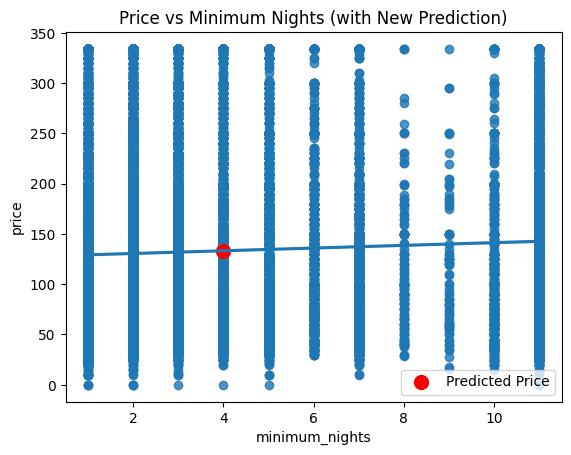

In [40]:
# 1. Define a new listing (for example, a listing that requires a minimum of 4 nights)
new_listing = pd.DataFrame({'minimum_nights': [4]})

# 2. Generate the predicted price for this new listing
predicted_price = model.predict(new_listing)

# 3. Plot the regression line and overlay the red prediction point
sns.regplot(x=df['minimum_nights'], y=df['price'])
plt.scatter(new_listing['minimum_nights'], predicted_price, color='red', marker='o', s=100, label='Predicted Price')
plt.title("Price vs Minimum Nights (with New Prediction)")
plt.legend()
plt.show()